# 07 · 真实公开CT：从文件与ROI到特征表

这是一例IBSI PAT1 CT与GTV-1的真实公开影像，不是合成NIfTI。目标是检查来源、几何、ROI覆盖与提取结果；没有临床结局，不做分类训练。原始来源 DOI：[10.17195/candat.2016.08.1](https://doi.org/10.17195/candat.2016.08.1)，镜像固定到IBSI数据仓库提交 `6da96021bc91faf4c0cb7fd7fa56a4225d2064a8`。

**原始文件为CC-BY-NC-3.0，具有署名和非商业限制。** 阅读[数据许可说明](../datasets.md)后再运行下载单元。MIT只适用于本项目软件。所有原始文件放在Git工作树之外；输出使用新目录。


## 1. 核对原生环境

在完整仓库内启动Jupyter。Python数组用于检查和绘图，NIfTI读取与特征计算使用Rust。


In [1]:
from pathlib import Path
import sys, tempfile, subprocess, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import ov_radiomics as rad
from ov_radiomics import image as rad_image, mask as rad_mask

REPO = Path(TUTORIAL_REPO_ROOT).resolve() if 'TUTORIAL_REPO_ROOT' in globals() else next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'examples/real/download_public_ct.py').is_file()), None)
if REPO is None:
    raise RuntimeError('请下载完整仓库，并在仓库内启动Jupyter。')
print(rad.backend_info())
assert rad.backend_info()['metrics_backend'] == 'rust'
output = Path(TUTORIAL_RUN_ROOT) if 'TUTORIAL_RUN_ROOT' in globals() else Path(tempfile.mkdtemp(prefix='radiomics-public-ct-'))
if 'TUTORIAL_RUN_ROOT' in globals():
    output.mkdir(parents=True, exist_ok=False)
from ov_radiomics._backend import resolve_backend
native_path = Path(resolve_backend('rust').__file__)
(output / 'tutorial-runtime.json').write_text(json.dumps({
    'backend': rad.backend_info(), 'native_sha256': hashlib.sha256(native_path.read_bytes()).hexdigest(),
    'interpreter': sys.executable, 'data_kind': 'real-public-ct-no-clinical-outcome'
}, indent=2), encoding='utf-8')
print('新的结果目录:', output)


{'metrics_backend': 'rust', 'rust_core_version': '0.1.0'}
新的结果目录: D:\radiomics-tutorial-validation\public-ct-execution-v1\07_public_ct\artifacts


## 2. 获取或复用已核验的真实文件

下列命令的 `--acknowledge-license` 是显式确认已阅读CC-BY-NC-3.0。首次运行约下载4MB；第二次复用同一缓存并重新校验SHA256。可以修改 `cache`，但不得放在Git工作树内。下载失败应修复网络或文件问题，不跳过哈希检查。

此CSV只有影像、mask和来源身份，没有人为生成的结局。


In [2]:
cache = Path(TUTORIAL_DATA_ROOT) if 'TUTORIAL_DATA_ROOT' in globals() else Path.home() / 'radiomics-tutorial-data' / 'ibsi-pat1'
subprocess.run([sys.executable, str(REPO / 'examples/real/download_public_ct.py'),
                '--output', str(cache), '--acknowledge-license'], check=True)
samples = rad.read_cohort(cache / 'cohort.csv')
display(samples[['ID', 'patient_id', 'image', 'mask']])
assert len(samples) == 1


,ID,patient_id,image,mask
0,PAT1-GTV1,PAT1,\\?\D:\radiomics-tutorial-validation\public-ct...,\\?\D:\radiomics-tutorial-validation\public-ct...


## 3. 检查完整几何和标签

`array` 的轴序为 `[z, y, x]`，几何的shape为 `[x, y, z]`。affine保留NIfTI的RAS世界坐标，不靠数组shape猜方向。这里没有自动重采样、配准或N4。真实数据若不对齐，应先显式处理并记录；不能仅调整绘图让它看起来匹配。


In [3]:
image = rad_image.read_nifti(samples.iloc[0]['image'])
mask = rad_mask.read_nifti(samples.iloc[0]['mask'])
print('影像几何:', image.geometry)
print('mask几何:', mask.geometry)
print('affine:\n', image.affine)
assert image.geometry['shape'] == mask.geometry['shape']
np.testing.assert_allclose(image.affine, mask.affine, atol=1e-6, rtol=0)
volume, labels = image.array, mask.array
print('数组shape(z,y,x):', volume.shape, 'mask标签:', np.unique(labels))
roi = labels == 1
assert roi.any(), '指定label=1的ROI为空'


影像几何: {'shape': [204, 201, 60], 'ndim': 3, 'affine': [[-0.9769999980926514, 0.0, 0.0, 174.39450073242188], [0.0, -0.9769999980926514, 0.0, 79.62550354003906], [0.0, 0.0, 3.0, -100.4000015258789], [0.0, 0.0, 0.0, 1.0]], 'unit': 'millimeter', 'diagnostics': [{'code': 'nifti_transforms', 'message': '{"coordinate_system":"RAS","qform":[[-0.9769999980926514,0.0,0.0,174.39450073242188],[0.0,-0.9769999980926514,0.0,79.62550354003906],[0.0,0.0,3.0,-100.4000015258789],[0.0,0.0,0.0,1.0]],"qform_code":2,"sform":[[-0.9769999980926514,0.0,0.0,174.39450073242188],[0.0,-0.9769999980926514,0.0,79.62550354003906],[0.0,0.0,3.0,-100.4000015258789],[0.0,0.0,0.0,1.0]],"sform_code":1}', 'severity': 'info', 'sample_id': None}]}
mask几何: {'shape': [204, 201, 60], 'ndim': 3, 'affine': [[-0.9769999980926514, 0.0, 0.0, 174.39450073242188], [0.0, -0.9769999980926514, 0.0, 79.62550354003906], [0.0, 0.0, 3.0, -100.4000015258789], [0.0, 0.0, 0.0, 1.0]], 'unit': 'millimeter', 'diagnostics': [{'code': 'nifti_transforms

## 4. 最大ROI截面与强度检查

这是数组索引视图，不是自动校正后的放射学方向图。预览用ROI最大的z截面，叠加真实mask边界；不根据影像强度重新分割。窗宽仅影响显示，不改变提取输入。


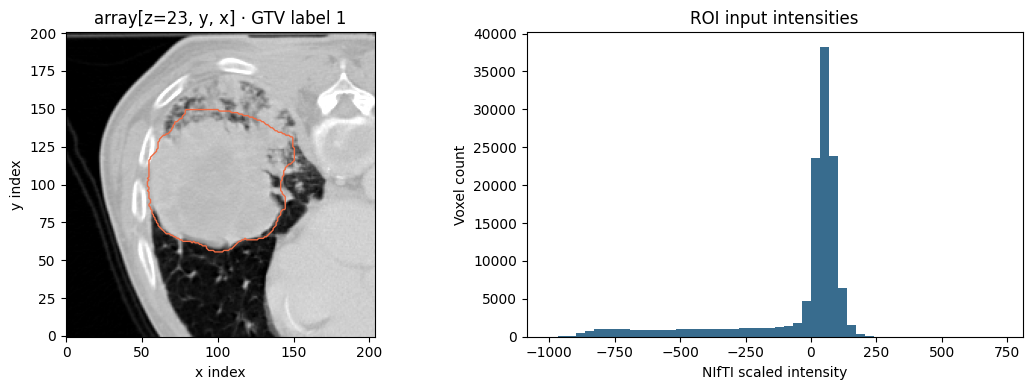

In [4]:
z = int(roi.sum(axis=(1, 2)).argmax())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(volume[z], cmap='gray', origin='lower', vmin=-1000, vmax=400)
axes[0].contour(roi[z], levels=[0.5], colors=['#ef6c44'], linewidths=1)
axes[0].set(title=f'array[z={z}, y, x] · GTV label 1', xlabel='x index', ylabel='y index')
axes[1].hist(volume[roi], bins=50, color='#386c8e')
axes[1].set(title='ROI input intensities', xlabel='NIfTI scaled intensity', ylabel='Voxel count')
fig.tight_layout()
fig.savefig(output / 'ct-roi-and-intensity.png', dpi=140)
plt.show()


## 5. 显式配置并调用共享提取器

先选择16项一阶＋11项基础形态，便于逐项阅读。bin width=25是本例演示配置，不是所有CT/MR/PET的通用建议。没有裁剪或重分割。完整55项统计/纹理加11项基础形态可把 `families` 改为 `None` 后在新目录重跑；不同配置不能混用验收结论。

PyRadiomics兼容配置是 `python_golden_v1`，不把它自动称作IBSI CT A–E标准配置。


In [5]:
config = {
    'extraction': {'profile': 'python_golden_v1',
        'discretization': {'method': 'fixed_width', 'width': 25.0},
        'aggregation': 'direction_mean', 'gldm_alpha': 0, 'voxel_array_shift': 0.0},
    'families': ['firstorder', 'shape_basic'],
    'labels': [1], 'preparation': [],
}
result = rad.extract(samples, params=config, backend='rust',
                     profile='python_golden_v1', n_jobs=1)
display(result.diagnostics)
display(result.features.T.rename(columns={0: 'value'}))
assert result.diagnostics['ok'].all()
assert len(result.features.columns) - 1 == 27


,ID,patient_id,ok,error,cache_key,quality
0,PAT1-GTV1,PAT1,True,,f02713f4f5db39aa9baf902c38f4a699b668e004614166...,"[{""code"": ""nifti_transforms"", ""message"": ""{\""c..."


,value
ID,PAT1-GTV1
original_firstorder_10Percentile,-434.0
original_firstorder_90Percentile,93.0
original_firstorder_Energy,6963080832.0
original_firstorder_Entropy,3.83534
original_firstorder_InterquartileRange,69.0
original_firstorder_Kurtosis,6.644312
original_firstorder_Maximum,723.0
original_firstorder_Mean,-46.88272
original_firstorder_MeanAbsoluteDeviation,160.104375


## 6. 保存文件、定义和可追溯参数

一个数值CSV不够说明研究流程。一起保存样本身份、特征定义、有效参数、质量记录与来源。公开CT输入保留在外置缓存，结果目录只包含本次导出。undefined特征的缺失标记要阅读质量记录，不能任意补成零。


In [6]:
result.save(output / 'extraction')
table = result.feature_table
table.save(output / 'features.csv')
table.metadata.to_csv(output / 'metadata.csv', index=False)
provenance = {
    'dataset': 'IBSI PAT1 CT/GTV-1', 'license': 'CC-BY-NC-3.0',
    'source_revision': '6da96021bc91faf4c0cb7fd7fa56a4225d2064a8',
    'input_sha256': {name: hashlib.sha256((cache/name).read_bytes()).hexdigest()
                     for name in ['image.nii.gz', 'mask.nii.gz']},
    'backend': rad.backend_info(), 'effective_config': config,
    'clinical_outcome_available': False,
}
(output / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
restored = rad.FeatureTable.read(output / 'features.csv')
pd.testing.assert_frame_equal(table.features, restored.features, check_exact=True)
print('结果文件:', [p.name for p in sorted(output.iterdir())])


结果文件: ['ct-roi-and-intensity.png', 'extraction', 'features.csv', 'features.csv.manifest.json', 'metadata.csv', 'provenance.json', 'tutorial-runtime.json']


## 7. 怎么解读，如何换成自己的数据

先核对ROI边界、单位、VoxelCount、Volume和强度范围，再看具体特征。这里仅一例，任何“分类AUC”“外部验证”或“预后概率”都是不成立的。对自己的影像创建队列CSV，按[文件工作流](../reference/user-guide/file-workflows.md)提取，再用真实患者结局和患者级划分建模。

自己的CT/ROI可直接运行：

```bash
python examples/real/nifti_extract.py --cohort my-cohort.csv --bin-width 25 --features basic --output results/my-extraction
```

重跑全部单元会生成新结果目录。只重跑保存单元可能触发防覆盖错误；请重建输出目录变量，勿删除已有研究结果来绕过错误。
